# Generating Word Clouds in Python

**Course:** MIAI507 – Natural Language Processing  
**Student:** Hadi Hijazi (105174)

Pipeline: scrape the Wikipedia article on *Large language models* → clean and lemmatize it with spaCy → count the most frequent words → visualize them as bar charts and word clouds.

## Setup

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import requests
import spacy
from bs4 import BeautifulSoup
from wordcloud import WordCloud

nlp = spacy.load("en_core_web_sm")

## Task 1 – Data Acquisition

To decide what to extract, I inspected the article in the browser's developer tools (right-click on a paragraph → **Inspect**).

**1. Where the article text is**

All the article content is inside `<div class="mw-parser-output">`, which sits in `<div id="mw-content-text">`. The sidebar, header and footer are outside it. Inside this container, each article section is wrapped in a `<section>` tag, and the readable text is in the `<p>` tags. The breadcrumb bar at the bottom of the screenshot shows this path for one paragraph: `div#mw-content-text` → `div.mw-parser-output` → `section` → `p`.

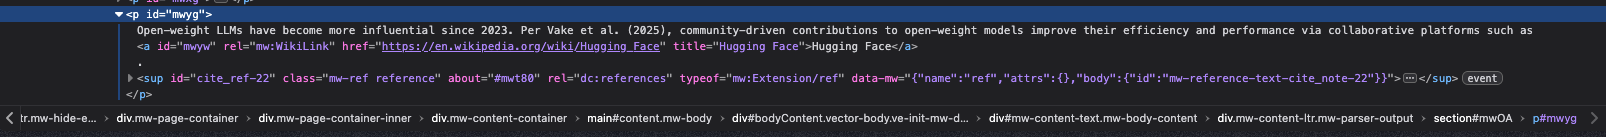

`find_all("p")` searches the whole container, including inside the sections, so it collects every paragraph of the article. Tables, the table of contents and the reference list use other tags, so keeping only `<p>` leaves them out.

**2. What I remove from the paragraphs**

Some elements inside the paragraphs are not part of the article text, so the function deletes them before extracting.

**Reference markers** such as `[1]`, `[2]`: links to the sources at the bottom of the page. Each one is a `<sup>` tag with the class `reference` (it also has `mw-ref`, but one class is enough for the selector `sup.reference`).

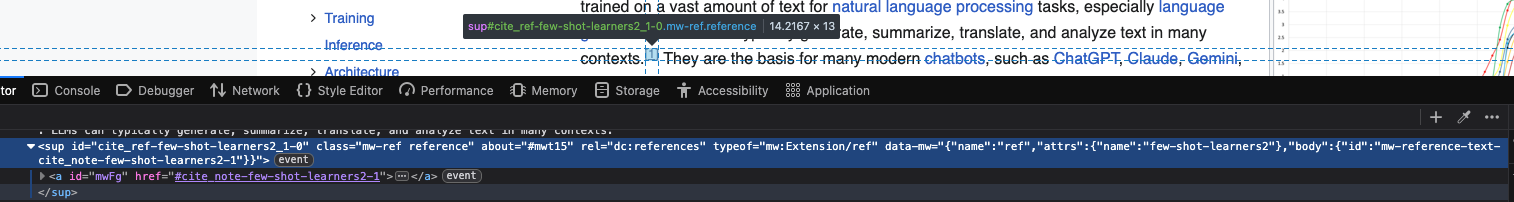

**Editor notes** such as *[citation needed]*: messages for Wikipedia editors, not article content. Each one is a `<sup>` tag with the class `noprint`. If kept, the words *citation* and *needed* would be counted. The article has 12 of them.

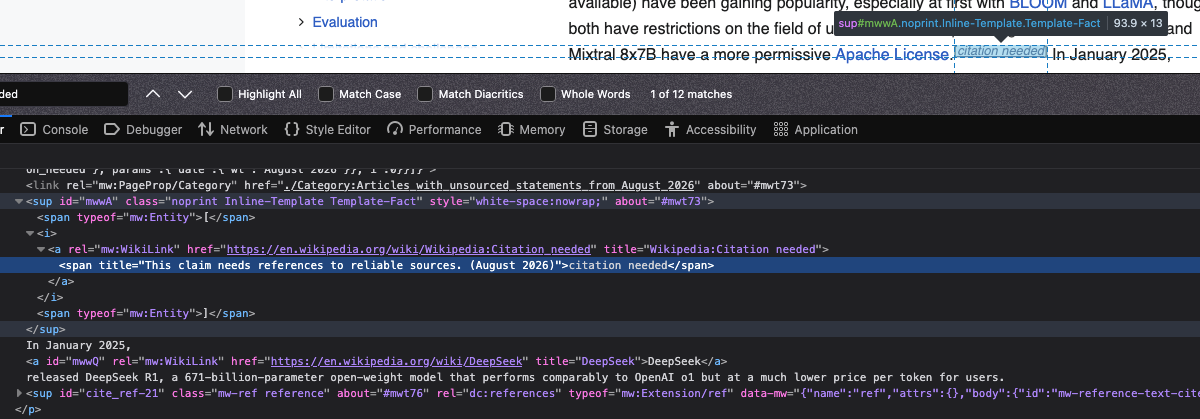

**Math formulas**: each formula is a `<span class="mwe-math-element">` that contains a hidden MathML copy and an image of the formula. Both carry the formula's LaTeX code, e.g. `{\displaystyle f(E(y))}` in the image's `alt` below. The hidden copy includes this code as text, so if kept, words like *displaystyle* appear in the word cloud.

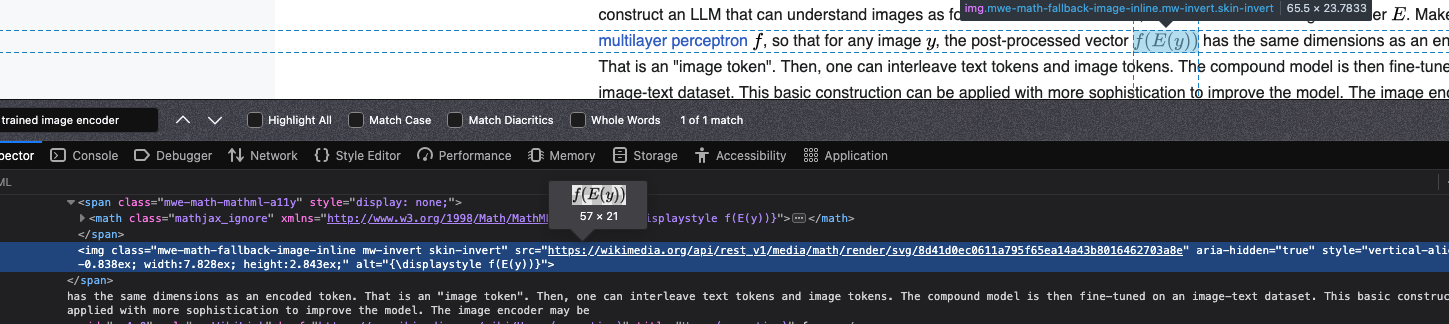

Wikipedia rejects requests without a descriptive `User-Agent`, so the request sets one.

In [2]:
URL = "https://en.wikipedia.org/wiki/Large_language_model"


def extract_wikipedia_text(url):
    """Download a Wikipedia article and return the text of its body paragraphs."""
    headers = {"User-Agent": "MIAI507-NLP-Assignment/1.0 (student project)"}
    response = requests.get(url, headers=headers, timeout=30)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    content = soup.select_one("#mw-content-text .mw-parser-output")

    # Drop reference markers [1], editor notes like [citation needed], and math formulas
    for tag in content.select("sup.reference, sup.noprint, .mwe-math-element"):
        tag.decompose()

    paragraphs = [p.get_text().strip() for p in content.find_all("p")]
    return "\n".join(p for p in paragraphs if p)


text = extract_wikipedia_text(URL)
print(f"Characters: {len(text):,} | Words: {len(text.split()):,}\n")
print(text[:800])

Characters: 45,468 | Words: 6,882

A large language model (LLM) is a machine learning model (typically a neural network) trained on a vast amount of text for natural language processing tasks, especially language generation. LLMs can typically generate, summarize, translate, and analyze text in many contexts. They are the basis for many modern chatbots, such as ChatGPT, Claude, Gemini, Grok, Qwen and DeepSeek.
LLMs are typically based on the transformer neural network architecture. Generative pre-trained transformers (GPTs) are a type of LLM that is pre-trained to predict the next word. GPTs are then often fine-tuned to follow instructions and to behave as assistants.
Biased or inaccurate training data can make an LLM's output less reliable. A software harness can provide LLMs with memory and access to tools such as web sea


## Task 2 – Text Preprocessing Using spaCy

1. **Cleaning** – lowercase the text, replace everything that is not a letter (punctuation, digits, special characters) with a space, and collapse repeated whitespace.
2. **spaCy pipeline** – tokenize, POS-tag and lemmatize the cleaned text.
3. **Filtering** – drop stop words (checked on both the word and its lemma, e.g. *is* → *be*) and single-letter leftovers.
4. **Nouns** – the second list keeps only tokens tagged `NOUN`.

Cleaning before lemmatization also merges *LLM* and *LLMs* into the single lemma `llm`.

In [3]:
def clean_text(text):
    """Lowercase and keep only letters and single spaces."""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)  # punctuation, numbers, special characters
    return re.sub(r"\s+", " ", text).strip()


def is_valid(token):
    return (
        token.is_alpha
        and len(token.text) > 1
        and not token.is_stop
        and not nlp.vocab[token.lemma_].is_stop
    )


def preprocess(text):
    """Return (all lemmatized tokens, lemmatized noun tokens) without stop words."""
    doc = nlp(clean_text(text))
    tokens = [token.lemma_ for token in doc if is_valid(token)]
    noun_tokens = [token.lemma_ for token in doc if is_valid(token) and token.pos_ == "NOUN"]
    return tokens, noun_tokens


tokens, noun_tokens = preprocess(text)
print(f"Tokens: {len(tokens):,} ({len(set(tokens)):,} unique)")
print(f"Noun tokens: {len(noun_tokens):,} ({len(set(noun_tokens)):,} unique)\n")
print("Tokens sample:     ", tokens[:15])
print("Noun tokens sample:", noun_tokens[:15])

Tokens: 3,971 (1,444 unique)
Noun tokens: 2,133 (689 unique)

Tokens sample:      ['large', 'language', 'model', 'llm', 'machine', 'learning', 'model', 'typically', 'neural', 'network', 'train', 'vast', 'text', 'natural', 'language']
Noun tokens sample: ['language', 'model', 'machine', 'learning', 'model', 'network', 'text', 'language', 'processing', 'task', 'language', 'generation', 'llm', 'translate', 'text']


## Task 3 – Word Frequency Analysis

`Counter.most_common(20)` gives the 20 most frequent lemmas in each list, shown as horizontal bar charts (most frequent at the top).

*Note:* spaCy lemmatizes *data* to its singular form *datum*.

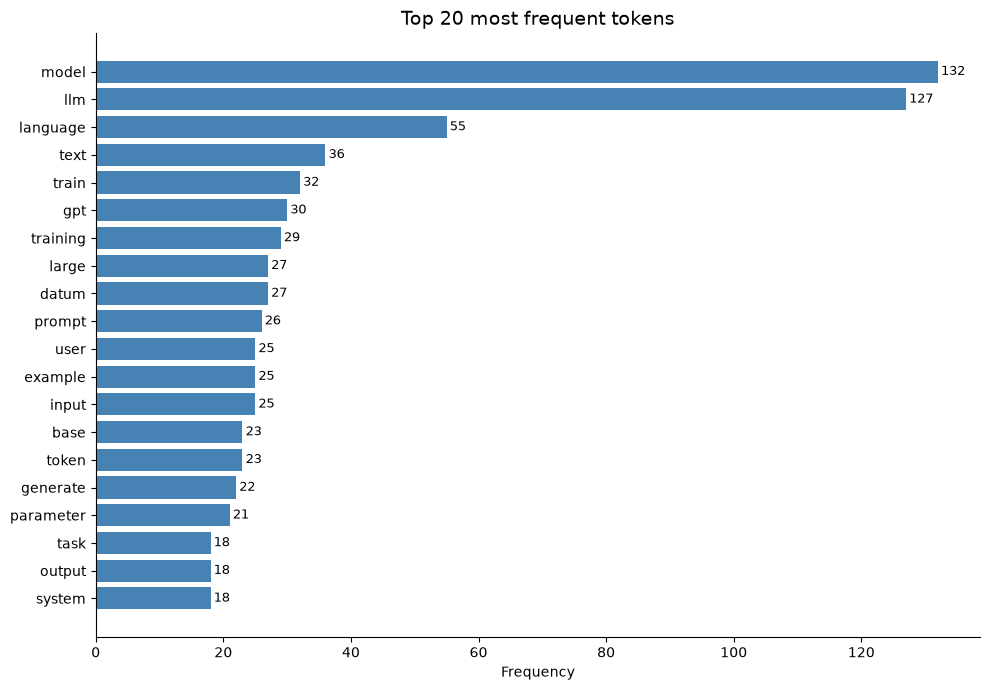

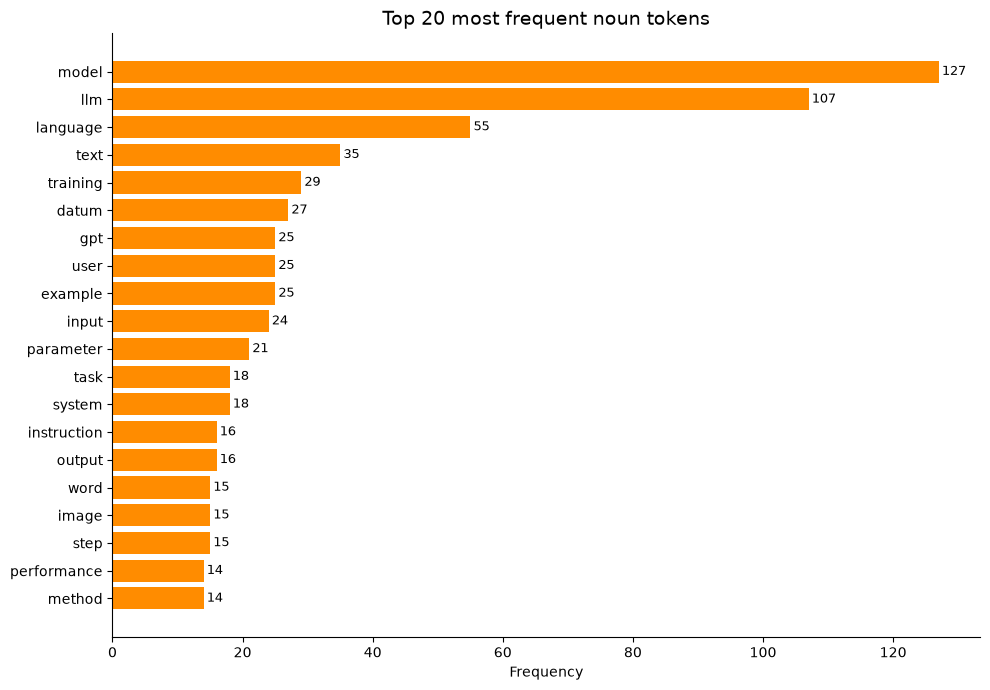

In [4]:
TOP_N = 20
token_counts = Counter(tokens)
noun_counts = Counter(noun_tokens)


def plot_top_words(counts, title, color):
    words, freqs = zip(*counts.most_common(TOP_N))
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(words[::-1], freqs[::-1], color=color)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Frequency")
    for i, f in enumerate(freqs[::-1]):
        ax.text(f + 0.5, i, str(f), va="center", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()


plot_top_words(token_counts, f"Top {TOP_N} most frequent tokens", "steelblue")
plot_top_words(noun_counts, f"Top {TOP_N} most frequent noun tokens", "darkorange")

## Task 4 – Word Cloud Visualization

`WordCloud.generate_from_frequencies` sizes each word by its count, so the clouds use exactly the frequencies computed in Task 3.

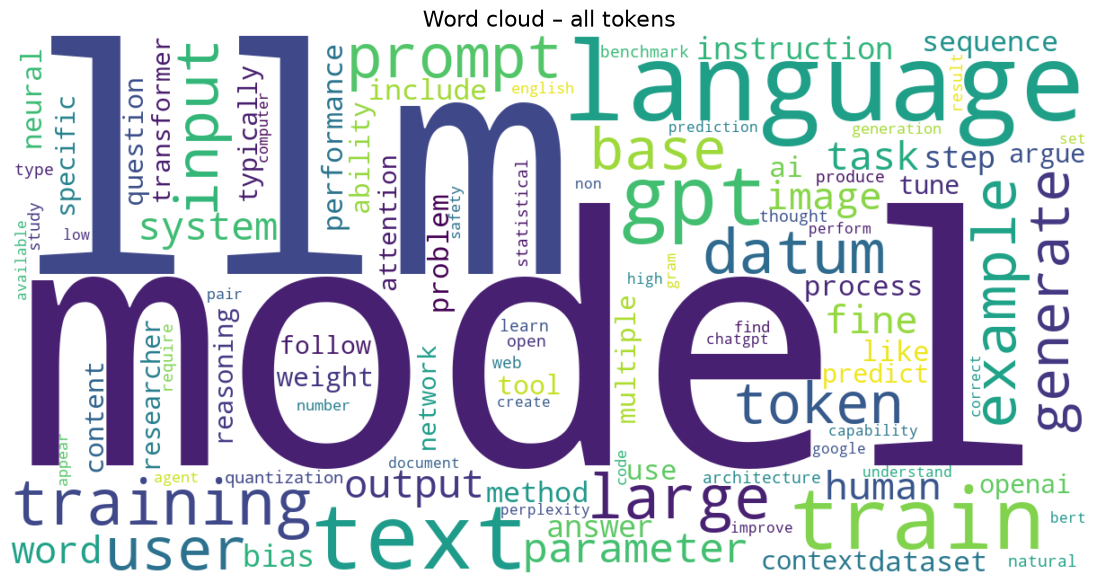

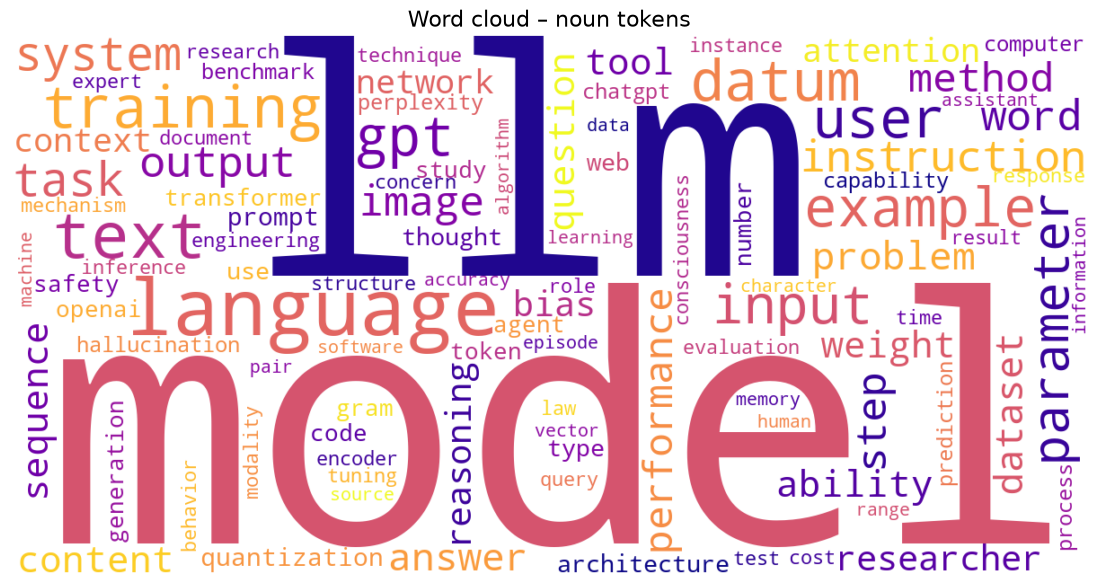

In [5]:
def show_word_cloud(counts, title, colormap):
    cloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        colormap=colormap,
        max_words=100,
        random_state=42,
    ).generate_from_frequencies(counts)
    plt.figure(figsize=(14, 7))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title, fontsize=16)
    plt.show()


show_word_cloud(token_counts, "Word cloud – all tokens", "viridis")
show_word_cloud(noun_counts, "Word cloud – noun tokens", "plasma")